# 01 · L'entrepôt ChargeDesk

**Objectif.** Regarder ce que contient l'entrepôt construit avec dbt, avant d'écrire les outils de l'agent.

**Ce qu'on vérifie.**
1. Les tables et leur provenance (registre de chargement).
2. Les sites et les bornes.
3. L'évolution des pannes dans le temps.
4. La fiabilité de la liste du soir : champion contre fallback.
5. Les bornes muettes.
6. La règle du soir courant : un résultat n'est visible qu'à partir de sa date de disponibilité.

L'entrepôt est ouvert **en lecture seule** : ce notebook ne modifie rien.

In [12]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path(os.environ.get("CHARGEDESK_DATA_DIR", r"C:\dev\chargedesk-data"))
con = duckdb.connect(str(DATA_DIR / "chargedesk.duckdb"), read_only=True)

def q(sql):
    return con.sql(sql).df()

pd.set_option("display.max_columns", 30)
REPLAY_START, REPLAY_END = pd.Timestamp("2021-08-31"), pd.Timestamp("2021-12-30")

## 1. Ce que contient l'entrepôt

In [13]:
q("""
    select schema_name as schema, table_name as table_, estimated_size as lignes
    from duckdb_tables()
    order by schema_name, table_name
""")

,schema,table_,lignes
0,marts,dim_post,92
1,marts,dim_site,13
2,marts,fct_drift_month,76
3,marts,fct_evening_list,2440
4,marts,fct_list_daily_hits,244
5,marts,fct_post_day,66698
6,marts,fct_post_signals,56673
7,marts,fct_silent_alert,23
8,raw,daily_target,66698
9,raw,features,56673


In [14]:
q("""
    select source, rows as lignes, left(sha256, 12) as empreinte, loaded_at as charge_le
    from raw.load_log
""")

,source,lignes,empreinte,charge_le
0,daily_target,66698,00ed0883c919,2026-10-14 19:13:16.933718
1,features,56673,0a51b5b3fdcc,2026-10-14 19:13:16.945145
2,replay_list,2440,d84a6a63305d,2026-10-14 19:13:16.945145
3,silent_posts,23,82c8aa3517d0,2026-10-14 19:13:16.945145
4,psi_by_month,19,ffe9d6ec46ef,2026-10-14 19:13:16.945145


Les vues `staging` n'apparaissent pas dans `duckdb_tables()` (ce sont des vues, pas des tables) : c'est normal.

**Constat :** l'entrepôt contient 6 tables brutes (`raw`) et 8 tables finales (`marts`). Chaque table finale a exactement le nombre de lignes de sa source (66 698 jours, 56 673 soirs, 2 440 lignes de listes, 23 alertes), et le registre garde l'empreinte des 5 fichiers chargés le 14 octobre 2026.

**Conséquence :** l'agent ne lira que le schéma `marts` : ce sera la liste des tables autorisées de l'outil SQL. Le registre `raw.load_log` fournit la provenance citée dans les réponses.

## 2. Les sites et les bornes

Vue globale sur les deux années (2020-2021), pour comprendre les données. L'agent, lui, ne verra jamais que la période jusqu'au soir courant.

In [15]:
q("select * from marts.dim_site order by n_posts desc, site")

,site,district,n_posts
0,Bus Station,Tongxiang,8
1,Expressway Service District C,Xiuzhou,8
2,Financial Industrial Park,Nanhu,8
3,Government Agency,Xiuzhou,8
4,Industrial Park,Tongxiang,8
5,Park A,Tongxiang,8
6,Park B,Tongxiang,8
7,Shopping Mall,Tongxiang,8
8,Tourist Attraction,Nanhu,8
9,Wholesale Market,Xiuzhou,8


In [16]:
q("""
    select site,
           count(distinct post_id)   as bornes,
           max(case when n_sessions > 0 then day end) as derniere_recharge,
           sum(n_sessions)           as recharges,
           sum(n_hw_faults)          as pannes_materielles,
           round(sum(n_hw_faults) / sum(n_sessions), 4) as taux_pannes
    from marts.fct_post_day
    group by site
    order by taux_pannes desc
""")

,site,bornes,derniere_recharge,recharges,pannes_materielles,taux_pannes
0,Wholesale Market,8,2021-12-31,34491.0,7195.0,0.2086
1,Shopping Mall,8,2021-12-31,56599.0,11037.0,0.1950
2,Park A,8,2021-12-31,27845.0,4058.0,0.1457
3,Expressway Service District B,4,2021-12-31,12400.0,1736.0,0.1400
4,Expressway Service District C,8,2021-12-31,50185.0,5506.0,0.1097
5,Tourist Attraction,8,2021-12-31,23659.0,2418.0,0.1022
6,Expressway Service District A,4,2021-12-31,15074.0,1467.0,0.0973
7,Financial Industrial Park,8,2021-12-31,18923.0,1797.0,0.0950
8,Bus Station,8,2021-12-31,60805.0,3642.0,0.0599
9,Government Agency,8,2021-12-31,36550.0,1809.0,0.0495


**Constat :** 13 sites répartis dans 3 districts (Tongxiang, Xiuzhou, Nanhu). Les totaux se recoupent avec la source : 441 060 recharges au total, comme dans ChargeTriage, et 44 845 pannes matérielles (10,2 %). Les écarts entre sites sont très forts : 20,9 % de pannes au Wholesale Market contre 3,3 % à l'Industrial Park. Le Shopping Mall concentre à lui seul 11 037 pannes (environ un quart du total) mais n'est que 2e en taux. La Bus Station a beaucoup de recharges (60 805) et peu de pannes (6,0 %). Le Technology Park n'a plus aucune recharge après le 28 septembre 2021.

**Conséquence :** « le site qui a le plus de problèmes » n'a pas de réponse unique : Shopping Mall en nombre, Wholesale Market en taux. C'est un vrai cas de question ambiguë pour le jeu d'évaluation : l'agent doit demander une précision ou donner les deux. Les outils renverront toujours le nombre **et** le taux.

## 3. Les pannes dans le temps

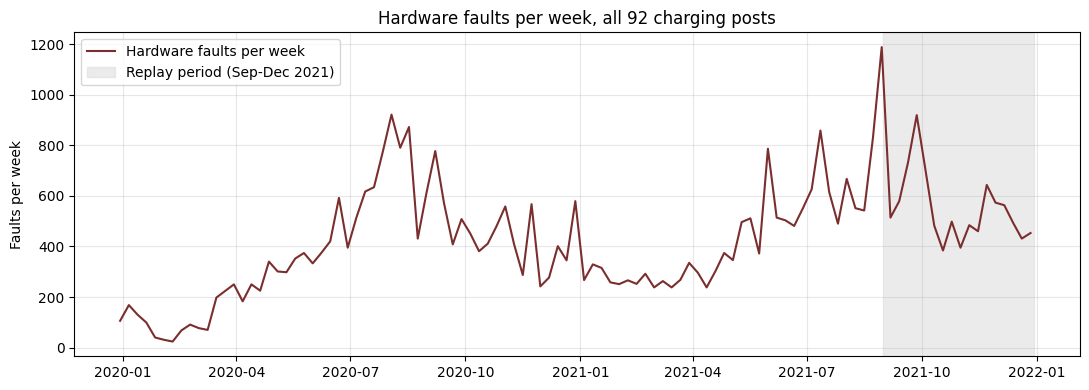

In [17]:
weekly = q("""
    select date_trunc('week', day) as week,
           sum(n_hw_faults)        as hw_faults,
           sum(n_sessions)         as sessions
    from marts.fct_post_day
    group by 1
    order by 1
""")
weekly["week"] = pd.to_datetime(weekly["week"])

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weekly["week"], weekly["hw_faults"], color="#7a2e2e", label="Hardware faults per week")
ax.axvspan(REPLAY_START, REPLAY_END, color="#d9d9d9", alpha=0.5, label="Replay period (Sep-Dec 2021)")
ax.set_title("Hardware faults per week, all 92 charging posts")
ax.set_ylabel("Faults per week")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Constat :** le nombre de pannes varie beaucoup d'une période à l'autre : moins de 100 par semaine au début de 2020, des pics vers 900 à l'été 2020, autour de 250 au début de 2021, puis le maximum (environ 1 190) fin août 2021, juste avant le rejeu. Pendant le rejeu, on reste entre 400 et 900 environ.

**Conséquence :** une hausse d'une semaine à l'autre peut suivre l'activité générale, sans rien dire d'une borne en particulier. Les comparaisons de périodes doivent donc donner le taux en plus du nombre, et l'agent doit décrire l'évolution sans en donner la cause : les données ne contiennent ni les interventions ni le contexte (fait et interprétation, pas causalité).

## 4. La liste est-elle fiable ? Champion contre fallback

In [18]:
hits = q("select * from marts.fct_list_daily_hits order by evening, model")
hits["evening"] = pd.to_datetime(hits["evening"])

summary = (hits.groupby("model")
               .agg(soirs=("evening", "nunique"),
                    bornes_listees=("n_listed", "sum"),
                    episodes_trouves=("n_hits", "sum"),
                    resultats_inconnus=("n_unknown", "sum"),
                    precision_moyenne=("precision", "mean"))
               .round(3))
summary

,soirs,bornes_listees,episodes_trouves,resultats_inconnus,precision_moyenne
model,,,,,
champion,122,1220,245,30,0.205
fallback,122,1220,158,50,0.135


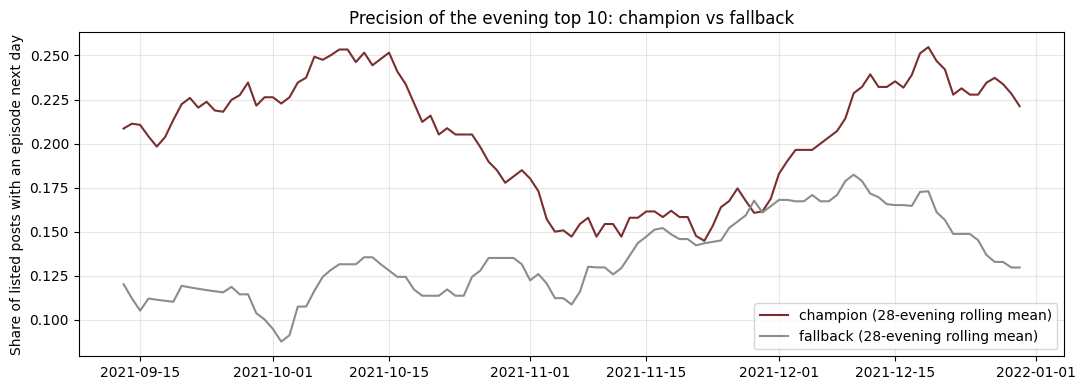

In [19]:
fig, ax = plt.subplots(figsize=(11, 4))
colors = {"champion": "#7a2e2e", "fallback": "#8c8c8c"}
for model, g in hits.groupby("model"):
    rolling = g.set_index("evening")["precision"].rolling(28, min_periods=14).mean()
    ax.plot(rolling.index, rolling.values, color=colors.get(model), label=f"{model} (28-evening rolling mean)")
ax.set_title("Precision of the evening top 10: champion vs fallback")
ax.set_ylabel("Share of listed posts with an episode next day")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Constat :** sur les 122 soirs du rejeu, les 10 bornes du champion ont eu 245 épisodes le lendemain, contre 158 pour le fallback (règle des pannes sur 7 jours) ; précision moyenne par soir de 20,5 % contre 13,5 %. Le champion reste devant presque tout le temps, mais l'écart varie : large mi-octobre (environ 0,25 contre 0,13), presque nul fin novembre (les deux courbes autour de 0,16), puis de nouveau net en décembre.

**Conséquence :** la réponse à « la liste est-elle fiable en ce moment ? » dépend du soir où l'on se place. L'outil de performance calculera la précision sur les soirs dont le résultat est déjà connu au soir courant (`outcome_known_from` ≤ soir courant), jamais sur toute la période. Les deux situations (avantage net, avantage presque nul) feront de bonnes questions de test.

## 5. Les bornes muettes

In [20]:
q("""
    select site, post_id, last_session_date as derniere_recharge,
           alert_date as alerte_le, days_silent as jours_sans_recharge
    from marts.fct_silent_alert
    order by alert_date, site, post_id
""")

,site,post_id,derniere_recharge,alerte_le,jours_sans_recharge
0,Park B,49,2021-08-19,2021-08-31,12
1,Shopping Mall,21,2021-08-19,2021-08-31,12
2,Wholesale Market,90,2021-08-19,2021-08-31,12
3,Expressway Service District C,80,2021-09-02,2021-09-09,7
4,Shopping Mall,22,2021-09-09,2021-09-16,7
5,Expressway Service District C,79,2021-09-14,2021-09-21,7
6,Shopping Mall,26,2021-09-22,2021-09-29,7
7,Technology Park,17,2021-09-28,2021-10-05,7
8,Technology Park,18,2021-09-28,2021-10-05,7
9,Technology Park,19,2021-09-28,2021-10-05,7


**Constat :** 23 alertes sur 9 sites. Les 3 premières (bornes 49, 21, 90) sont levées dès le premier soir du rejeu, après 12 jours de silence : ces bornes étaient déjà arrêtées avant. Ensuite, chaque alerte arrive après 7 jours sans recharge. Deux sites passent en entier en alerte, avec deux histoires différentes. Le Technology Park (4 bornes, alerte le 5 octobre) ne repart jamais : sa dernière recharge est le 28 septembre (section 2). Le Tourist Attraction (borne 4 le 5 décembre, puis les 7 autres le 20 décembre) **reprend** avant la fin de l'année : sa dernière recharge est le 31 décembre.

**Conséquence :** une borne muette n'est pas une borne en panne, c'est une absence d'activité. L'agent doit regrouper les alertes par site (un site entier muet est un signal plus fort qu'une borne isolée). Une alerte n'est pas un état : la table donne le jour de l'alerte, pas sa fin. Pour dire si une borne est **toujours** muette, l'agent regarde sa dernière recharge connue au soir courant dans `fct_post_day`. Exemple pour le jeu d'évaluation : « le Tourist Attraction est-il toujours à l'arrêt ? » vaut **oui** le 21 décembre et **non** le 31.

⚠️ **Point de vigilance trouvé ici : une fuite dans `dim_post`.** Les colonnes `last_session_day`, `last_day`, `total_sessions` et `total_hw_faults` sont calculées sur les deux années entières. Au soir du 5 octobre, `last_session_day` d'une borne qui fonctionne vaut 31 décembre 2021 : une date future. Correction : `dim_post` ne garde que les attributs fixes (borne, site, district, premier jour) ; tout ce qui est daté se calcule depuis `fct_post_day` jusqu'au soir courant.

## 6. La règle du soir courant

Aperçu de la règle que les outils de l'agent appliqueront en phase 5 : **rien dont la date de disponibilité dépasse le soir courant**.
On regarde la liste du soir du 5 octobre 2021, vue depuis deux soirs différents.

In [21]:
def evening_list(evening, current_evening, model="champion"):
    df = q(f"""
        select rank, post_id, site, round(score, 3) as score,
               episode_next_day, outcome_known_from
        from marts.fct_evening_list
        where evening = date '{evening}' and model = '{model}'
        order by rank
    """)
    hidden = pd.to_datetime(df["outcome_known_from"]) > pd.Timestamp(current_evening)
    df["episode_next_day"] = df["episode_next_day"].astype("object")
    df.loc[hidden, "episode_next_day"] = "pas encore connu"
    return df.drop(columns="outcome_known_from")

print("Vue depuis le soir du 2021-10-05 (le lendemain n'a pas encore eu lieu) :")
display(evening_list("2021-10-05", current_evening="2021-10-05"))
print("Vue depuis le soir du 2021-10-06 (le resultat est connu) :")
display(evening_list("2021-10-05", current_evening="2021-10-06"))

Vue depuis le soir du 2021-10-05 (le lendemain n'a pas encore eu lieu) :


,rank,post_id,site,score,episode_next_day
0,1,23,Shopping Mall,0.356,pas encore connu
1,2,27,Shopping Mall,0.346,pas encore connu
2,3,81,Expressway Service District C,0.318,pas encore connu
3,4,84,Expressway Service District C,0.309,pas encore connu
4,5,54,Bus Station,0.221,pas encore connu
5,6,83,Expressway Service District C,0.220,pas encore connu
6,7,51,Park B,0.216,pas encore connu
7,8,35,Park A,0.214,pas encore connu
8,9,34,Park A,0.186,pas encore connu
9,10,50,Park B,0.185,pas encore connu


Vue depuis le soir du 2021-10-06 (le resultat est connu) :


,rank,post_id,site,score,episode_next_day
0,1,23,Shopping Mall,0.356,True
1,2,27,Shopping Mall,0.346,True
2,3,81,Expressway Service District C,0.318,False
3,4,84,Expressway Service District C,0.309,False
4,5,54,Bus Station,0.221,False
5,6,83,Expressway Service District C,0.220,False
6,7,51,Park B,0.216,False
7,8,35,Park A,0.214,True
8,9,34,Park A,0.186,False
9,10,50,Park B,0.185,False


**Constat :** le soir du 5 octobre, la borne en tête est la 23 (Shopping Mall, score 0,356), suivie de la 27 (même site). Vue depuis le 5 octobre, aucun résultat n'est visible ; vue depuis le 6, on voit que 3 bornes sur 10 ont eu un épisode (23, 27 et 35). Ce même soir, les 4 bornes du Technology Park passent en alerte sans figurer dans la liste.

**Conséquence :** la règle du soir courant fonctionne et se résume à une comparaison de dates. En phase 5, elle passera dans le code des outils, avec un test. La simulation du cadrage (borne 47 en tête) était fictive ; les questions du jeu d'évaluation utiliseront les vraies valeurs, comme celles-ci. Le scénario « Technology Park muet mais absent de la liste » existe bien dans les données.

## Ce qu'on retient

- L'entrepôt est complet et cohérent avec ChargeTriage (441 060 recharges, 92 bornes, 13 sites, 122 soirs de rejeu).
- **Nombre et taux ne désignent pas les mêmes sites** : les outils donneront toujours les deux, et la question « quel site a le plus de problèmes » est un vrai cas ambigu.
- **La fiabilité de la liste change avec le temps** : le champion est devant en moyenne (20,5 % contre 13,5 %), mais presque à égalité fin novembre.
- **Les bornes muettes se lisent par site, et une alerte n'est pas un état** : le Technology Park s'arrête pour de bon, le Tourist Attraction s'arrête puis reprend.
- **Une fuite a été trouvée et corrigée dans `dim_post`** : une dimension ne garde que des attributs fixes ; tout ce qui dépend du temps se calcule jusqu'au soir courant.

In [22]:
con.close()